# Seaborn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Import data (and setting up types)

In [2]:
es_df = (pd.read_csv('files/ecommerce_sales.csv', index_col='order_id', parse_dates=['date']).sort_values('date'))

es_df = es_df.astype({
    'city': 'category',
    'category': 'category',
    'price': 'float',
    'revenue': 'float',
    'units': 'int'
    })

es_df.dtypes

date        datetime64[us]
city              category
category          category
price              float64
units                int64
revenue            float64
dtype: object

## Distribution Plots

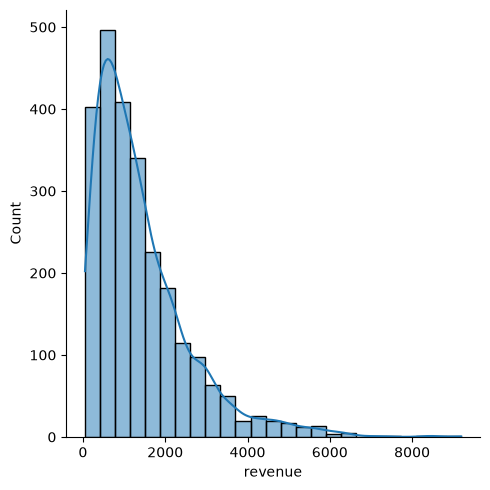

In [3]:
sns.displot(es_df['revenue'], kde=True, bins = 25)  # Kernel Density Estimation (the line in diag)

#### Joint Plot

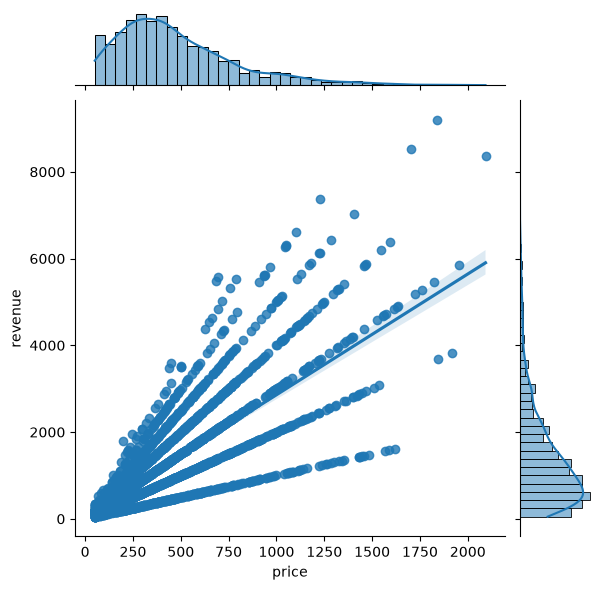

In [4]:
sns.jointplot(x='price', y='revenue' , data= es_df, kind='reg')
#examples of kind, reg = regression line, kde = kernel density, hex= hexagon distribution

#### KDE Plot

<Axes: xlabel='price', ylabel='Density'>

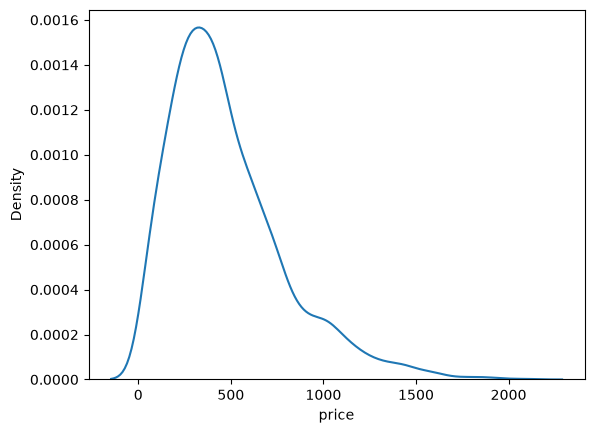

In [5]:
sns.kdeplot(es_df['price'])

### Pair Plots 

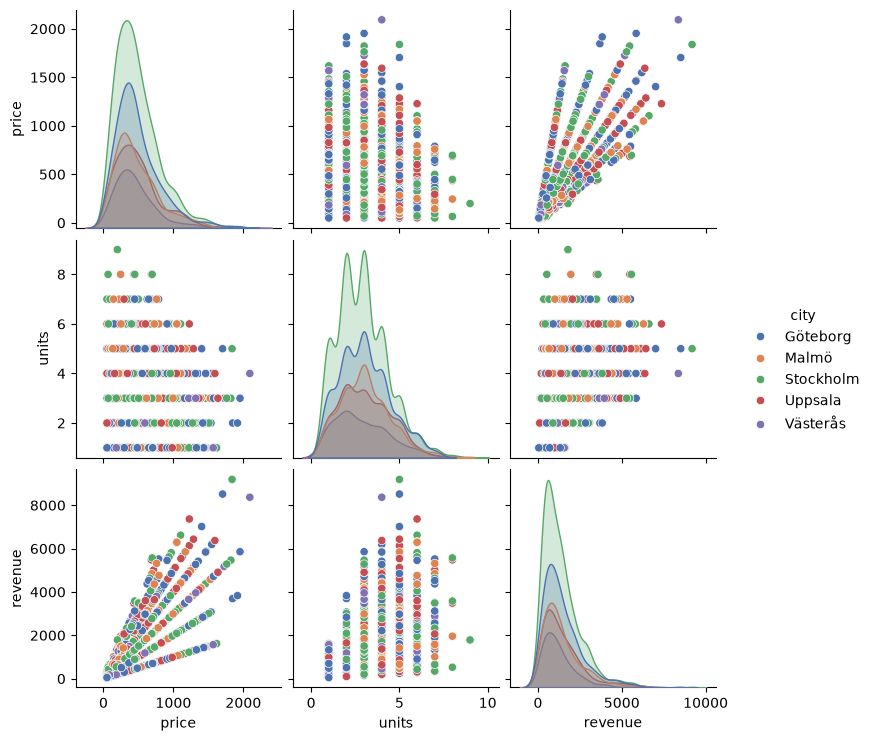

In [6]:
sns.pairplot(es_df,hue = 'city', palette='deep')
# creates relational plots for all numeric values

## Styling

<Figure size 800x400 with 0 Axes>

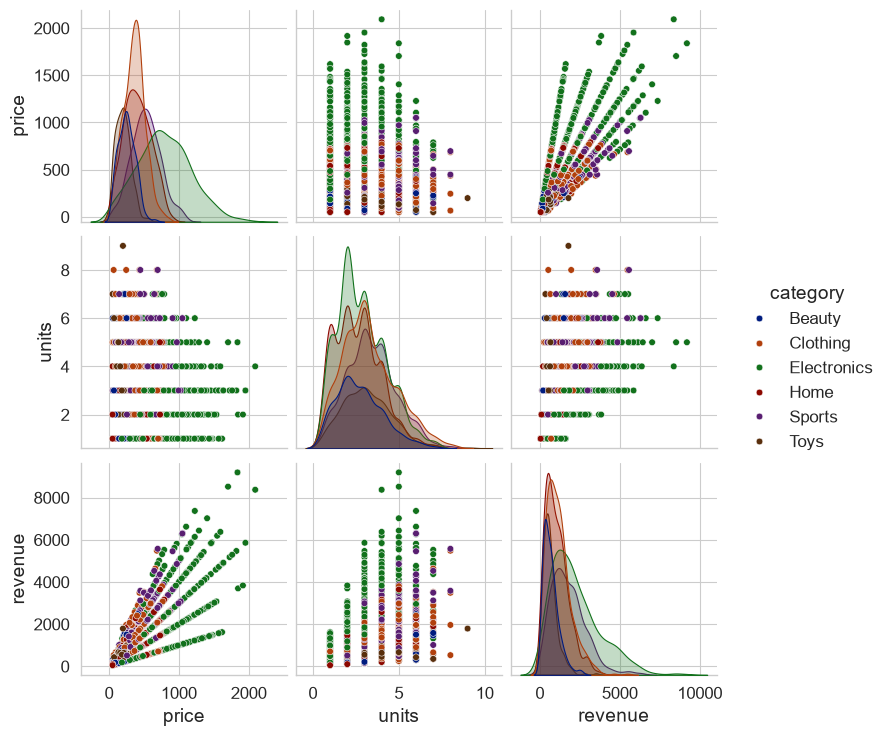

In [7]:
sns.set_style('whitegrid')
plt.figure(figsize= (8,4))
sns.set_context('paper', font_scale=1.4)

sns.pairplot(es_df,hue = 'category', palette='dark')

# Categorical Plots

### Bar Plots

<Axes: xlabel='city', ylabel='revenue'>

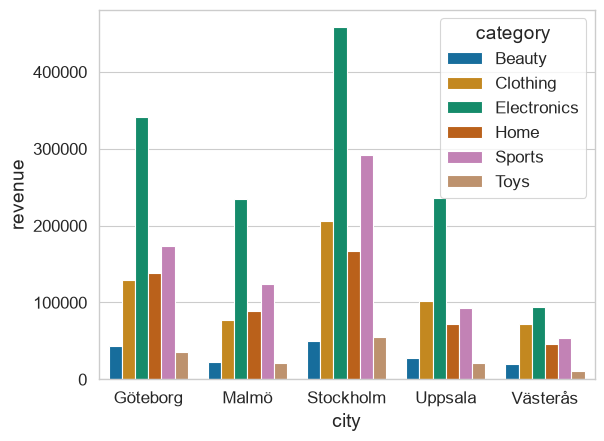

In [8]:
sns.barplot(x='city', y='revenue', data=es_df, palette='colorblind',hue='category', estimator=np.sum, errorbar=None)
# estimator default is the mean value

### Count Plot

C:\Users\fdasfda\AppData\Local\Temp\ipykernel_30556\224052540.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='city',data=es_df, palette='muted')


<Axes: xlabel='city', ylabel='count'>

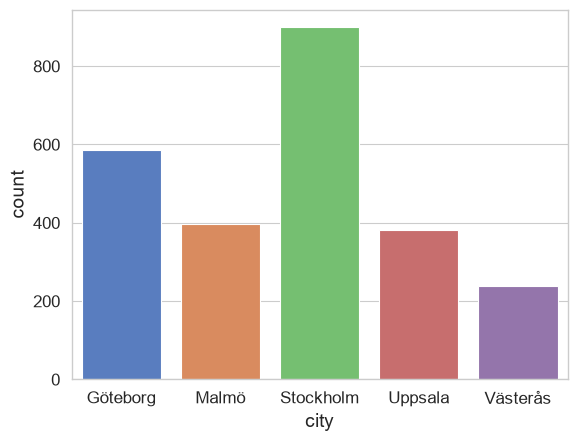

In [9]:
sns.countplot(x='city',data=es_df, palette='muted')

### Box Plot


C:\Users\fdasfda\AppData\Local\Temp\ipykernel_30556\2413730852.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='price', data=es_df, palette='Paired')


<Axes: xlabel='category', ylabel='price'>

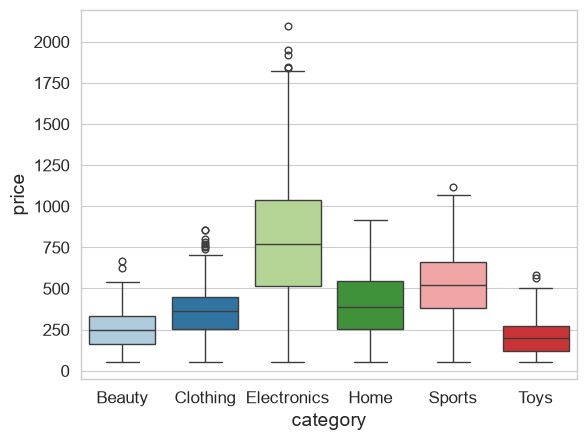

In [10]:
sns.boxplot(x='category', y='price', data=es_df, palette='Paired')
# note! Paired is with capital P

### Violin Plot

<Axes: xlabel='date', ylabel='revenue'>

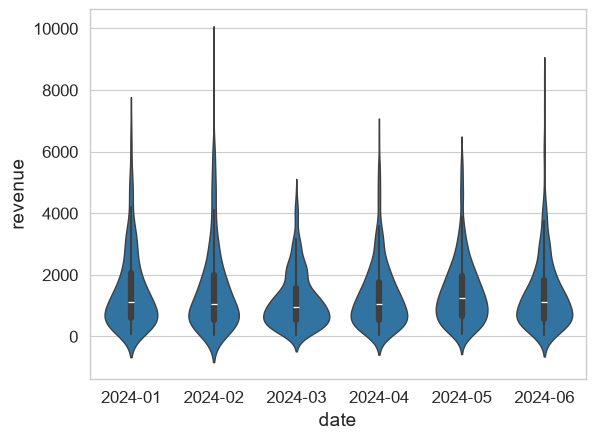

In [11]:
sns.violinplot(x=es_df['date'].dt.to_period('M'), y='revenue', data=es_df)
# if used with hue for pairs you can also use split=True to get left/right

### Strip Plot

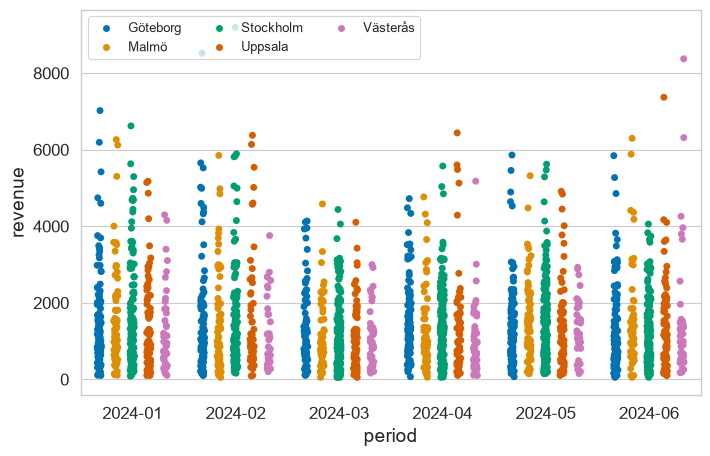

In [12]:
plt.figure(figsize=(8,5))
df_sorted = es_df.sort_values('date').copy()
df_sorted['period'] = df_sorted['date'].dt.to_period('M')

sns.stripplot(x='period',y='revenue',data=df_sorted, palette='colorblind', jitter= True, hue='city', dodge=True)
plt.legend(
    loc='upper center',          # Förankringspunkt i boxens över- och mittkant
    bbox_to_anchor=(0.28, 1.0),  # 0.35 flyttar den lite till vänster (0.50 är exakt mitten). 1.0 är i absoluta toppen.
    fontsize=9,            # Gör texten mindre ('small' eller t.ex. 9)
    ncol=3                     # Lägger städerna på en horisontell rad istället för en lång lista, numb of columns
)

### Swarm Plot

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Beauty'),
  Text(1, 0, 'Clothing'),
  Text(2, 0, 'Electronics'),
  Text(3, 0, 'Home'),
  Text(4, 0, 'Sports'),
  Text(5, 0, 'Toys')])

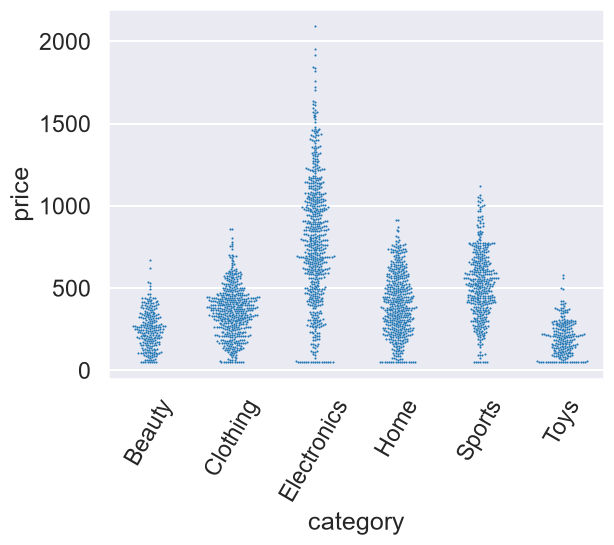

In [13]:
sns.set_style('darkgrid')
sns.set_context('talk')
sns.swarmplot(x='category', y='price', data=es_df, size=1.5)
plt.xticks(rotation=60)

## Matrix Plots

### Heatmaps

            price     units   revenue
price    1.000000 -0.045798  0.746944
units   -0.045798  1.000000  0.523025
revenue  0.746944  0.523025  1.000000


<Axes: >

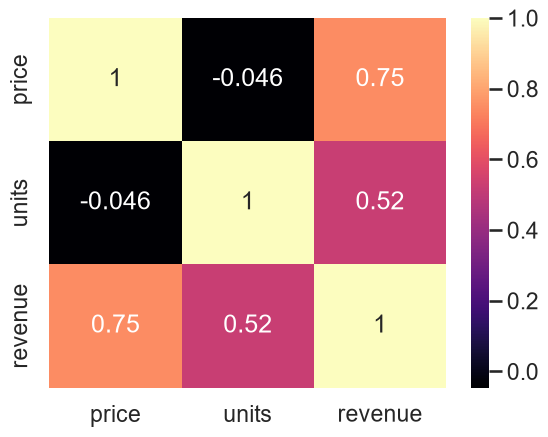

In [14]:
es_mx = es_df.corr(numeric_only=True)
print(es_mx)

sns.heatmap(es_mx, annot=True, cmap='magma')

city      Göteborg      Malmö  Stockholm    Uppsala  Västerås
date                                                         
2024-01  162733.76  112625.48  231480.69  105786.37  51457.02
2024-02  143196.98   97203.92  183273.71   85550.63  39236.79
2024-03  106729.36   71195.67  186238.86   76579.99  46858.12
2024-04  151167.50   85268.35  212650.20   82322.65  48786.13
2024-05  150909.69  110216.98  223885.31   98987.57  48165.61
2024-06  144282.36   91415.92  189673.17  102251.21  62637.23


<Axes: xlabel='city', ylabel='date'>

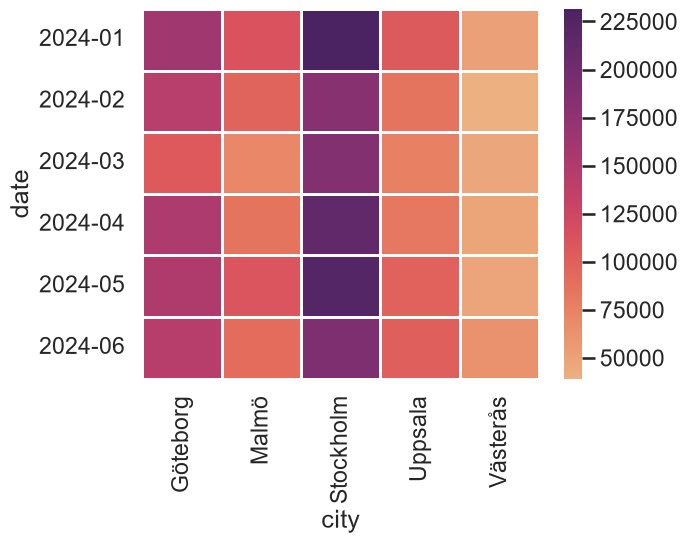

In [15]:
es_df2 = es_df.pivot_table(
    index=es_df['date'].dt.to_period('M'),
    columns='city', 
    values='revenue', 
    aggfunc='sum')

print(es_df2)
sns.heatmap(es_df2, cmap='flare', linecolor='white', linewidth=1)


### Cluster Map

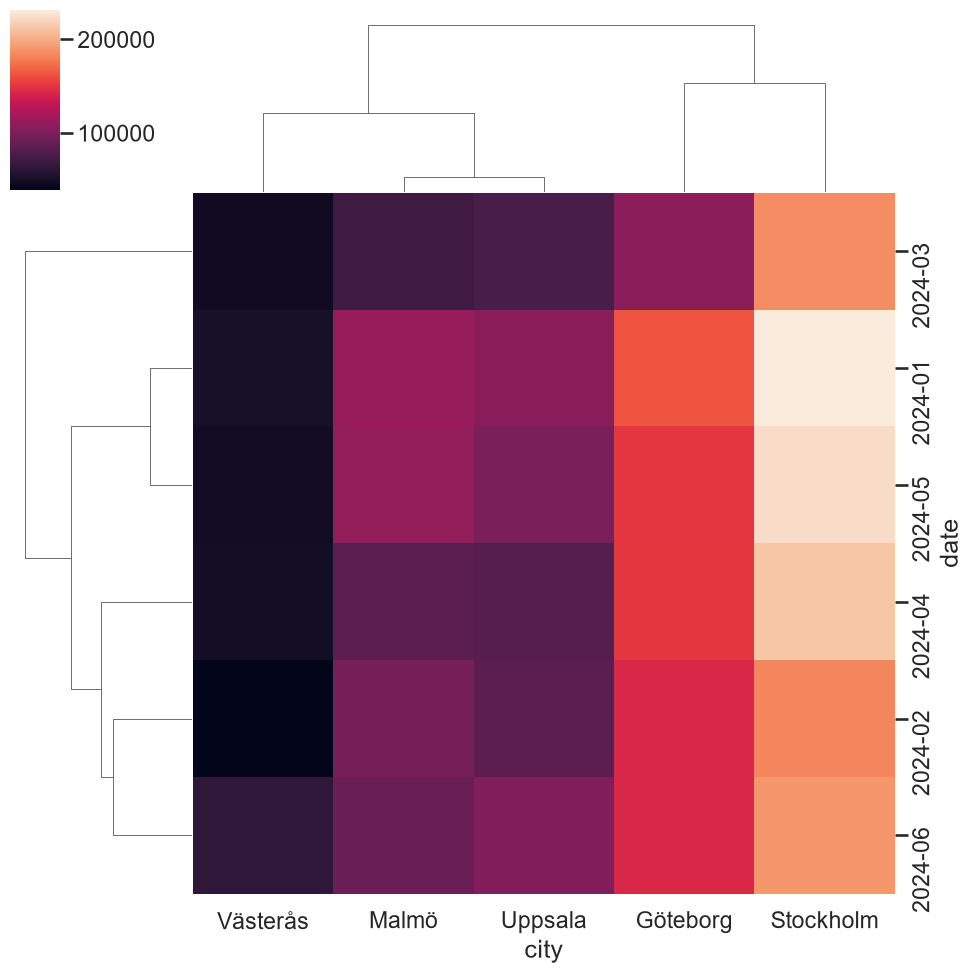

In [16]:
sns.clustermap(es_df2, cmap='rocket')

### Pair Grid

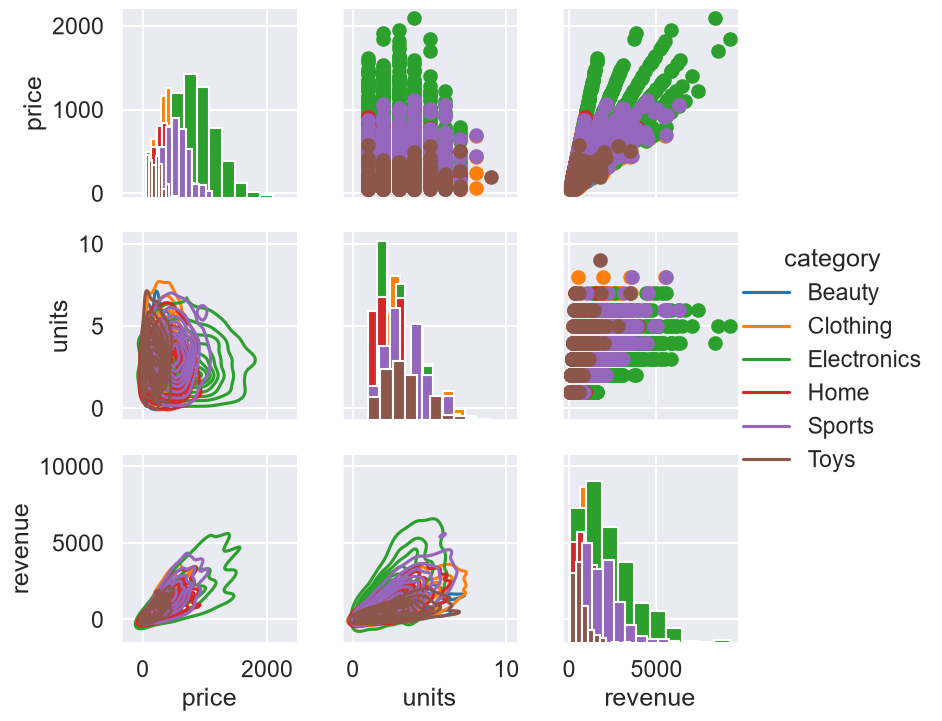

In [17]:
es_df_g = sns.PairGrid(es_df, hue='category')
es_df_g.map_diag(plt.hist)
es_df_g.map_upper(plt.scatter)
es_df_g.map_lower(sns.kdeplot)
es_df_g.add_legend()

### Facet Grid

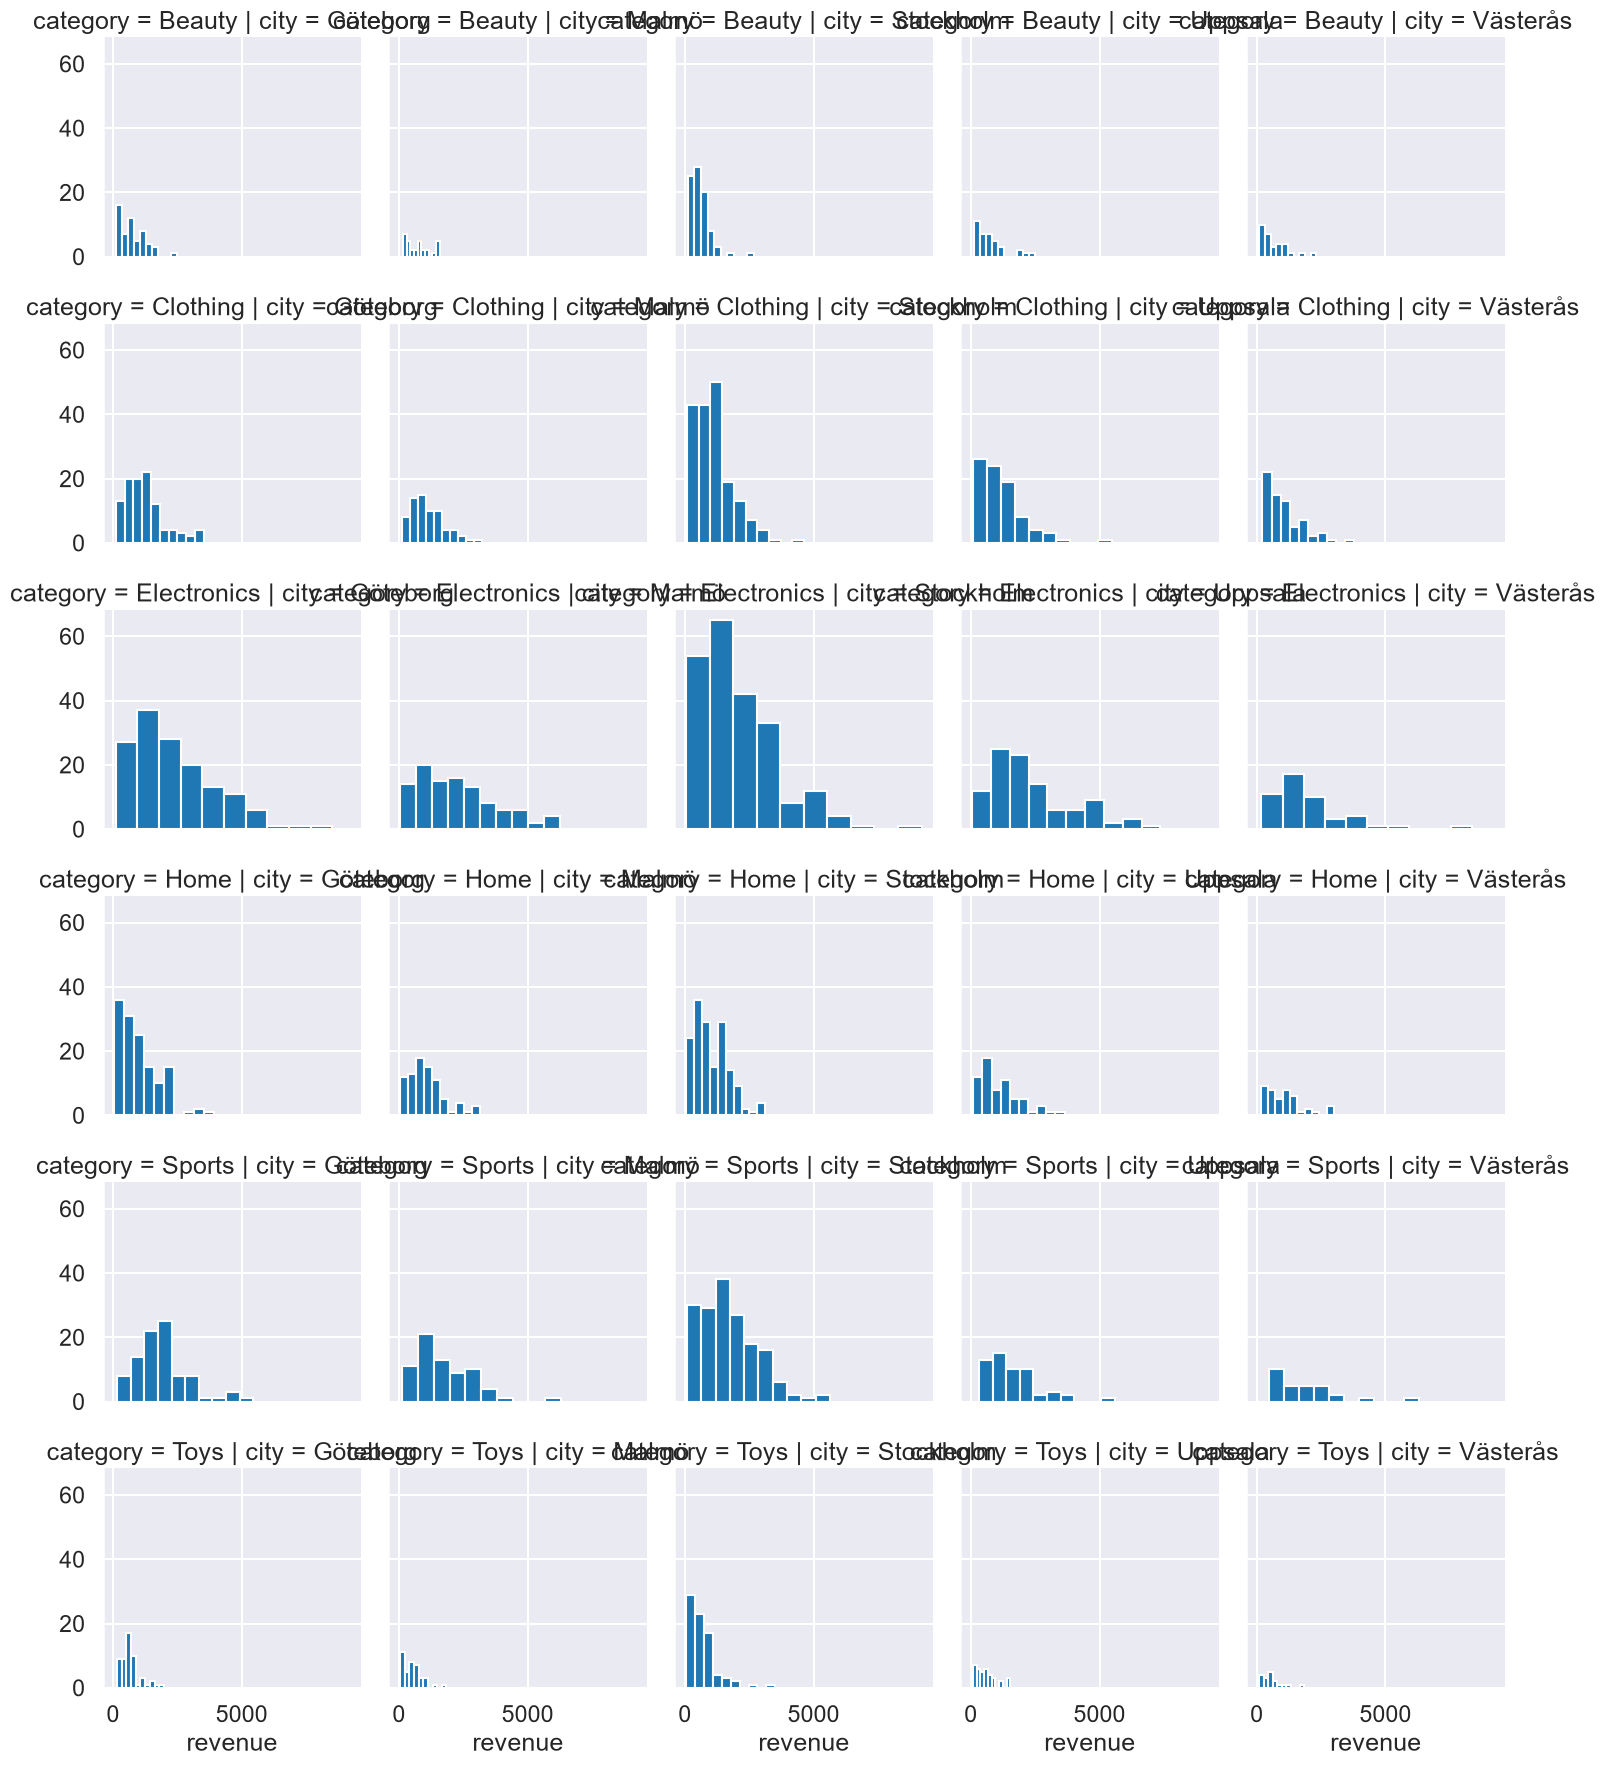

In [18]:
es_fg = sns.FacetGrid(es_df, col='city', row='category')
es_fg.map(plt.hist, 'revenue')


### Regression Plot

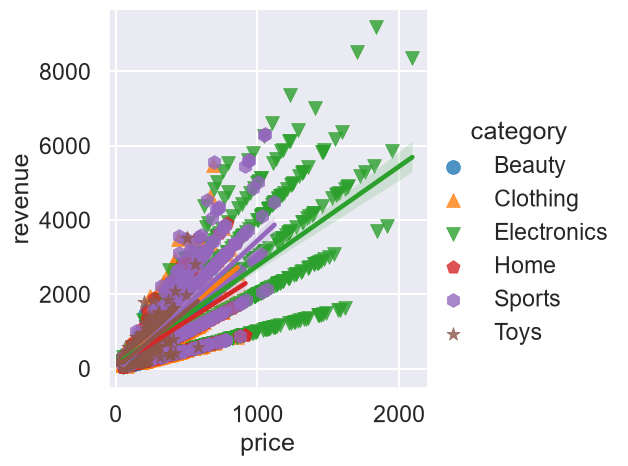

In [19]:
sns.lmplot(x='price', y='revenue', data=es_df, hue='category' , markers=['o','^','v','p','h','*'], 
           scatter_kws={'s':100, 'linewidths': 0.5})

### Line Plots

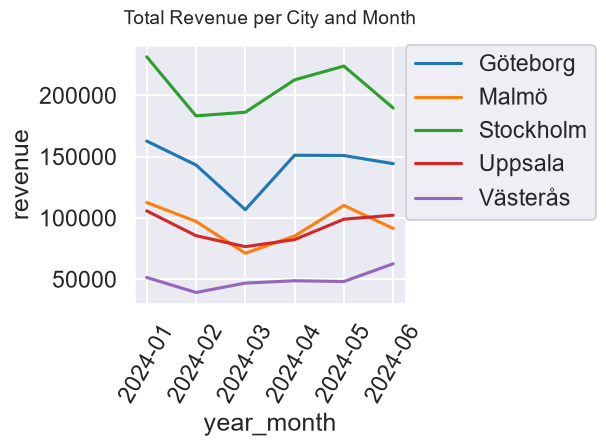

In [22]:
# creates a new column with month and year and makes the timedates to strings
es_df['year_month'] = es_df['date'].dt.to_period('M').astype(str)

sns.lineplot(data=es_df, x='year_month', y='revenue', hue = 'city', estimator=np.sum, errorbar=None)

# 3. Flytta ut legenden till höger om diagrammet
plt.legend(
    loc='upper left',          # Fästpunkt: Övre vänstra hörnet av legend-boxen
    bbox_to_anchor=(1, 1),  # X=1 (precis till höger om diagrammet), Y=1 (i linje med överkanten)
    borderaxespad=0            # Tar bort marginalen mellan diagramkanten och rutan för perfekt linjering
)
plt.title('Total Revenue per City and Month', fontsize=14, pad=15)
plt.xticks(rotation=60) # Roterar månaderna så de syns snyggt
plt.tight_layout()      # Automatiskt extra utrymme så inget klipps bort vid sparande/visning
plt.show()


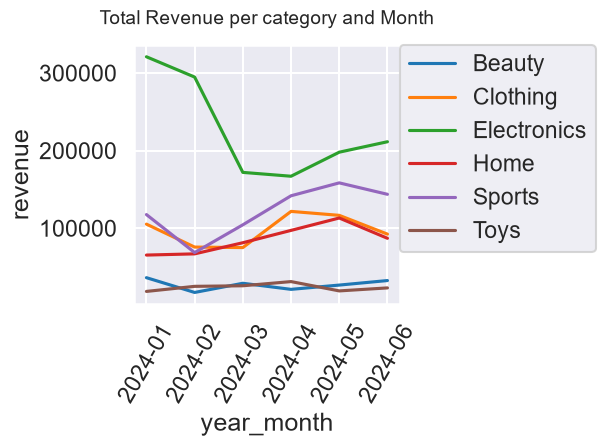

In [21]:
# creates a new column with month and year and makes the timedates to strings
sns.lineplot(data=es_df, x='year_month', y='revenue', hue = 'category', estimator=np.sum, errorbar=None)

# Moves the legend to the right of diag
plt.legend(
    loc='upper left',          # Fastening point: Upper left corner of the legend box
    bbox_to_anchor=(1, 1),  # X=1 (precis till höger om diagrammet), Y=1 (i linje med överkanten)
    borderaxespad=0            # Tar bort marginalen mellan diagramkanten och rutan för perfekt linjering
)

plt.title('Total Revenue per category and Month', fontsize=14, pad=15)

plt.xticks(rotation=60) # Rotates the months to not overlap
plt.tight_layout()      # Automatiskt extra utrymme så inget klipps bort vid sparande/visning
plt.show()
